RECONNECTION CODE:

system("git init")

system("git config --global user.email 'guinto36ruth@gmail.com'")
system("git config --global user.name 'rm-cg'")

system("git remote add origin https://YOUR_TOKEN@github.com/rm-cg/maritime-anisotropy-lgcp-R.git")

system("git branch -M main")

system("git add .")

system("git commit -m 'feat:'")

system("git push -u origin main 2>&1", intern = TRUE)



CONTINUE COMMIT:

system("git add .")

system("git commit -m 'feat: insert-your-next-feature-name-here'")

system("git push origin main 2>&1", intern = TRUE)

DAY 1

Download CSV vessel distributions from Global Fishing Watch

> **AMIHAN** (JUNE 1 - SEPT 31)


> **HABAGAT** (DEC 1 - FEB 31)



DAY 2

In [4]:
# 1. Install the core spatial modeling packages
install.packages(c("spatstat", "sf", "inlabru"))

# 2. Load the packages into your active R session
library(spatstat)
library(sf)
library(inlabru)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘proxy’, ‘sp’, ‘deldir’, ‘polyclip’, ‘spatstat.sparse’, ‘goftest’, ‘abind’, ‘tensor’, ‘e1071’, ‘wk’, ‘splancs’, ‘spatstat.data’, ‘spatstat.univar’, ‘spatstat.geom’, ‘spatstat.random’, ‘spatstat.explore’, ‘spatstat.model’, ‘spatstat.linnet’, ‘spatstat.utils’, ‘classInt’, ‘s2’, ‘units’, ‘fmesher’, ‘MatrixModels’, ‘plyr’


Loading required package: spatstat.data

Loading required package: spatstat.univar

spatstat.univar 3.2-0

Loading required package: spatstat.geom

spatstat.geom 3.8-2

Loading required package: spatstat.random

spatstat.random 3.5-0

Loading required package: spatstat.explore

Loading required package: nlme

spatstat.explore 3.8-1

Loading required package: spatstat.model

Loading required package: rpart

spatstat.model 3.7-1

Loading required package: spatstat.linnet

spatstat.linnet 3.5-1


spatstat 3.6-1 
For an introduction to spatstat, type ‘beginne

In [5]:
# 1. Define the geometric bounding box for Manila Bay
manila_bay_window <- owin(xrange = c(120.5, 121.0), yrange = c(14.3, 14.8))

# 2. Print the object to confirm it is stored in memory
print(manila_bay_window)

window: rectangle = [120.5, 121] x [14.3, 14.8] units


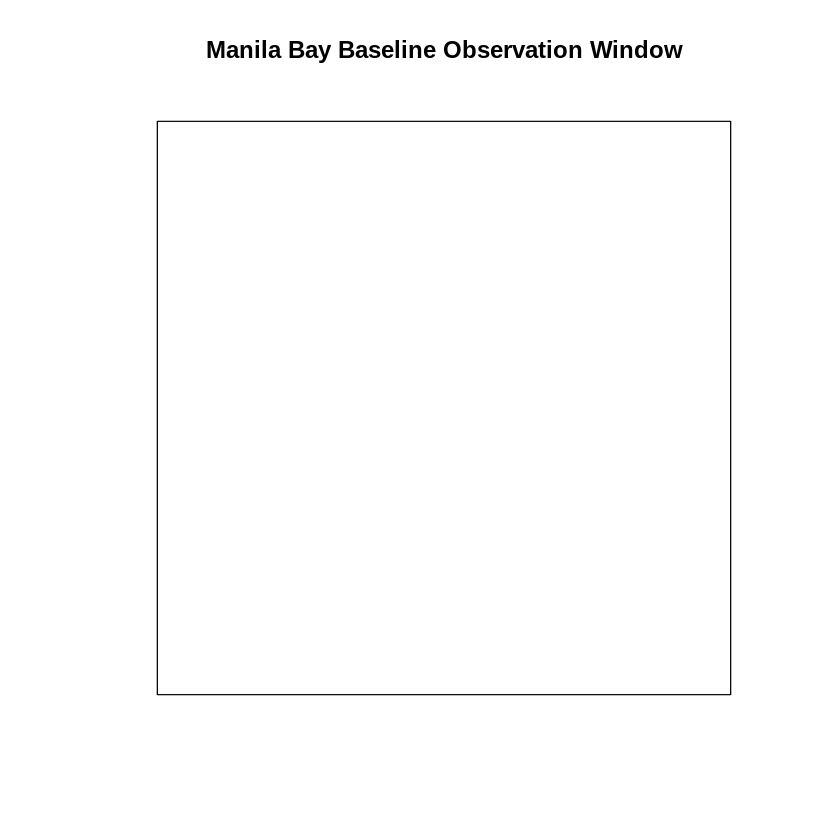

In [6]:
# Plot the mathematical observation window for Manila Bay
plot(manila_bay_window, main = "Manila Bay Baseline Observation Window")

$ W \subset \mathbb{R}^2 $

DAY 3

In [8]:
# 1. Install and load the geodata package to pull GADM shapefiles directly
install.packages("geodata")
library(geodata)
library(sf)

# 2. Download the high-resolution Philippine boundary shapefile (Level 0)
phl_boundary <- gadm(country = "PHL", level = 0, path = tempdir())

# 3. Convert it to an 'sf' spatial object so it is ready to be intersected
phl_coast_sf <- st_as_sf(phl_boundary)

# 4. Print a confirmation
print("Philippine Coastline successfully imported and converted to an sf object!")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘terra’


Loading required package: terra

terra 1.9.34


Attaching package: ‘terra’


The following objects are masked from ‘package:spatstat.geom’:

    area, delaunay, is.empty, rescale, rotate, shift, where.max,
    where.min


Cached as: /tmp/RtmpdVi9N8/gadm/gadm41_PHL_0_pk.rds



[1] "Philippine Coastline successfully imported and converted to an sf object!"


In [9]:
# 1. Define your Manila Bay bounding box as an 'sf' object
# (Matching the exact coordinates from Day 2)
manila_bbox <- st_bbox(c(xmin = 120.5, xmax = 121.0, ymin = 14.3, ymax = 14.8),
                       crs = st_crs(phl_coast_sf))
manila_bbox_sf <- st_as_sfc(manila_bbox)

# 2. Intersect (crop) the massive Philippine coastline down to just your bounding box
manila_bay_coast <- st_intersection(phl_coast_sf, manila_bbox_sf)

# 3. Print a confirmation message
print("Successfully cropped the Philippine coastline to the Manila Bay bounding box!")

Warning message:
“attribute variables are assumed to be spatially constant throughout all geometries”


[1] "Successfully cropped the Philippine coastline to the Manila Bay bounding box!"


In [11]:
# 1. Strip the geographic CRS tag so spatstat stops blocking the conversion
manila_bay_coast_flat <- st_set_crs(manila_bay_coast, NA)

# 2. Convert the flattened 'sf' landmass object into a spatstat 'owin' object
land_owin <- as.owin(manila_bay_coast_flat)

# 3. Subtract the landmass from the baseline bounding box to create the pure marine window
marine_window <- setminus.owin(manila_bay_window, land_owin)

# 4. Print a confirmation message
print("Successfully generated the non-convex marine observation window!")

[1] "Successfully generated the non-convex marine observation window!"


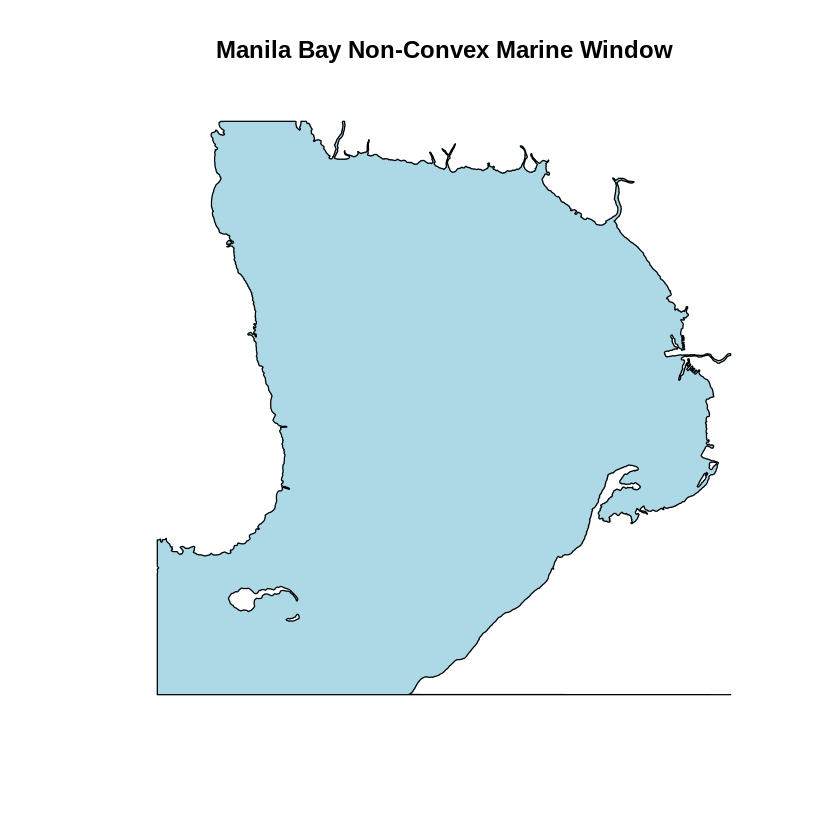

In [12]:
# Plot the non-convex marine observation window
plot(marine_window, main = "Manila Bay Non-Convex Marine Window", col = "lightblue")